# 02 - Speaker-Listener: when your teammate keeps changing

**Setting: cooperative, one common reward.**
* The **speaker** sees the colour of the goal landmark but cannot move. Its action is a message of 3 numbers.
* The **listener** moves, sees the landmarks and the message, but not the goal.
* Both get the same reward every step: **minus the squared distance listener -> goal**.

The message has no built-in meaning: the two have to invent one *while both are learning*.
All runs here are pre-trained; only the last cell trains (about a minute).

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from marl.analysis import *          # load_run, describe_networks, evolution_frames, plot_curves, ...
from marl.render import show_video
plt.rcParams["figure.dpi"] = 90

## Step 1 - the obvious approach: each agent learns on its own (IDDPG)

Actions are continuous, so each agent runs its own **DDPG**: a deterministic actor (plus exploration noise), a critic that
scores actions, a replay buffer and slowly-updated target networks. "Independent" means each agent's critic only sees **its own**
observation and action - the other agent is treated as part of the environment.

In [2]:
iddpg = load_run("sl_iddpg")
describe_networks(iddpg)

network                  used by     layers               hidden act.  output                      params
actor                    speaker_0   3 -> 64 -> 64 -> 3   ReLU         sigmoid -> action in [0,1]  4611  
actor                    listener_0  11 -> 64 -> 64 -> 5  ReLU         sigmoid -> action in [0,1]  5253  
critic Q (action value)  speaker_0   6 -> 64 -> 64 -> 1   ReLU         scalar                      4673  
critic Q (action value)  listener_0  16 -> 64 -> 64 -> 1  ReLU         scalar                      5313  
total parameters: 19,850


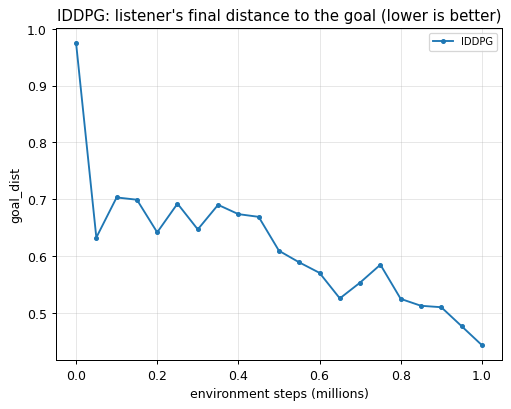

In [3]:
plot_curves([iddpg], "goal_dist", title="IDDPG: listener's final distance to the goal (lower is better)");

### Watch it learn
The same episode replayed with the policy from later and later in training. The speaker's message is printed at the bottom.

In [4]:
show_video(evolution_frames(iddpg, k=5), fps=10)

### What goes wrong
* The listener **wanders between landmarks** for a long time and rarely commits to the right one.
* For a long stretch the speaker sends **almost the same message for every goal** (see the "language" plot further down) - there is nothing to decode yet.
* Learning is slow and noisy.

**Why:** each agent's critic learns "how good was my action?" while the *other* agent keeps changing. When the speaker changes what a
message means, the listener's experience - and its critic - become outdated. From each agent's point of view the world is
**non-stationary**: the same situation and action lead to different outcomes over time.

## Step 2 - MADDPG: let the critics see everybody

One change: during training, each agent's critic sees **all** observations and **both** agents' actions, *Q_i(s, a_speaker, a_listener)*.
The other agent's behaviour is now an *input* rather than a hidden, changing part of the world.
The actors are unchanged and still act on their own observation only (**centralised training, decentralised execution**).

In [5]:
maddpg = load_run("sl_maddpg")
describe_networks(maddpg)        # compare the critic inputs with IDDPG above

network                  used by     layers               hidden act.  output                      params
actor                    speaker_0   3 -> 64 -> 64 -> 3   ReLU         sigmoid -> action in [0,1]  4611  
actor                    listener_0  11 -> 64 -> 64 -> 5  ReLU         sigmoid -> action in [0,1]  5253  
critic Q (action value)  speaker_0   22 -> 64 -> 64 -> 1  ReLU         scalar                      5697  
critic Q (action value)  listener_0  22 -> 64 -> 64 -> 1  ReLU         scalar                      5697  
total parameters: 21,258


In [6]:
show_video(evolution_frames(maddpg, k=5), fps=10)

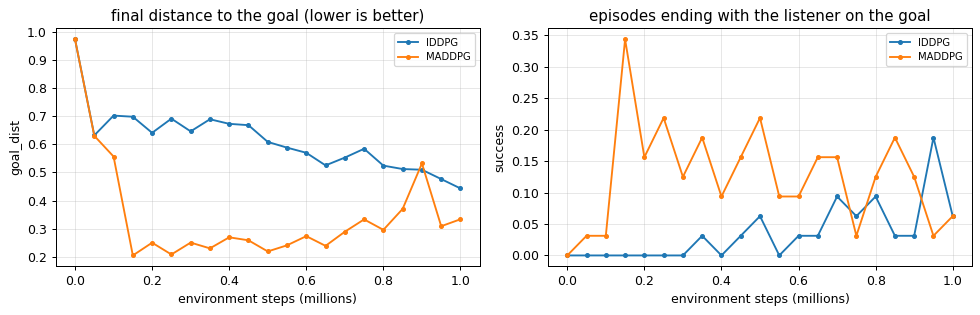

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
plot_curves([iddpg, maddpg], "goal_dist", ax=ax[0], title="final distance to the goal (lower is better)")
plot_curves([iddpg, maddpg], "success", ax=ax[1], title="episodes ending with the listener on the goal")
plt.tight_layout()

MADDPG learns the task several times faster (we checked three random seeds). Note it is not perfectly stable either -
its curve has dips. The next plots show what happens in those moments.

## Looking inside: the speaker's "language"
The speaker only ever sees the goal colour, so its whole policy is **three messages** (one per goal).
* **separation** - how different the messages for different goals are (0 = the listener cannot possibly tell goals apart)
* **drift** - how much the messages changed since the previous snapshot (every change is something the listener must re-learn)

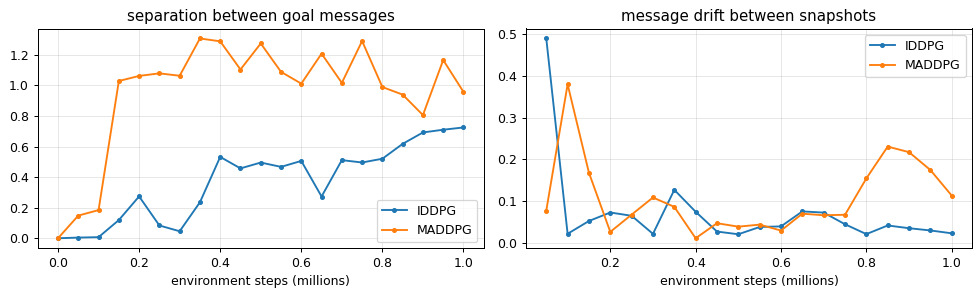

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for run in (iddpg, maddpg):
    steps, msgs = speaker_messages(run)
    ax[0].plot(steps / 1e6, message_separation(msgs), marker="o", ms=3, label=run["config"]["label"])
    ax[1].plot(steps[1:] / 1e6, message_drift(msgs), marker="o", ms=3, label=run["config"]["label"])
ax[0].set_title("separation between goal messages"); ax[1].set_title("message drift between snapshots")
for a in ax: a.set_xlabel("environment steps (millions)"); a.grid(alpha=.3); a.legend()
plt.tight_layout()

## The moving-target test
Pair the **listener from training time *t*** with the **speaker from training time *s***, and measure how close the listener gets.
* good values only near the diagonal = a listener only understands the speaker it grew up with
* a row that is good everywhere = the speaker's language stayed stable while that listener was trained

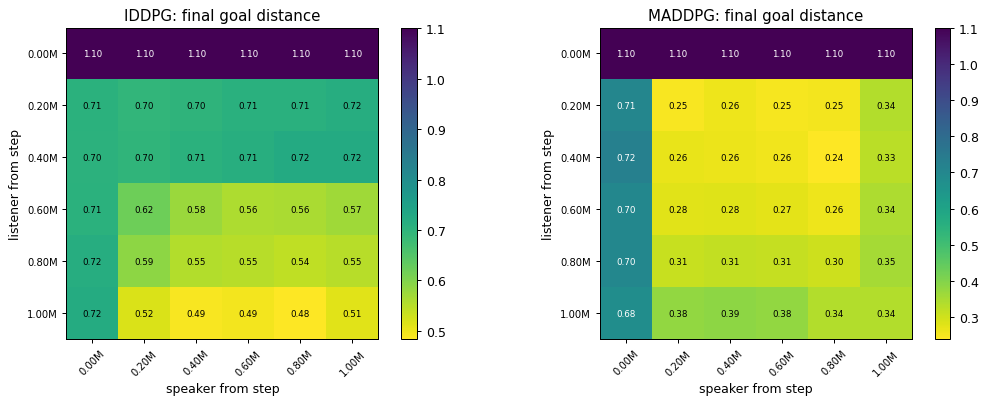

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, run in zip(ax, (iddpg, maddpg)):
    M, steps = moving_target_matrix(run, k=6, episodes=64)
    plot_matrix(M, steps, ax=a, title=f"{run['config']['label']}: final goal distance",
                xlabel="speaker from step", ylabel="listener from step")
plt.tight_layout()

### One listener, two speakers
The MADDPG listener from 0.65M steps, paired first with the speaker it trained with, then with the speaker from the end of training.
Same goal, different message - the listener no longer understands it.

In [10]:
listener = snapshot(maddpg, 650_000)
frames = []
for seed in (3, 7):
    for spk_step, txt in ((650_000, "speaker from 0.65M (trained together)"), (1_000_000, "speaker from 1.0M (language changed)")):
        pair = MixedPolicy([snapshot(maddpg, spk_step), listener])     # agent order: speaker, listener
        frames += video(pair, "speaker_listener", {}, seed=seed, title=txt)
show_video(frames, fps=8)

## Takeaways
* Independent learners treat each other as part of a changing world -> slow, noisy learning (**non-stationarity**).
* A critic that sees everybody's actions (MADDPG) makes the learning problem stationary from the critic's point of view and learns much faster.
* Even then the agents keep changing *together* - a teammate's "language" can shift and leave you behind.

## Try it yourself (about a minute on a laptop CPU)
A short MADDPG run from scratch. Change `critic="local"` to train IDDPG instead.

[toy] step         0 wall_time=1 goal_dist=0.799 success=0 return_speaker=-21.3 return_listener=-21.3


[toy] step    20,000 wall_time=6.9 goal_dist=0.572 success=0.0625 return_speaker=-12.2 return_listener=-12.2


[toy] step    40,000 wall_time=14.4 goal_dist=0.665 success=0 return_speaker=-13.6 return_listener=-13.6


[toy] step    60,000 wall_time=21.8 goal_dist=0.59 success=0.0625 return_speaker=-11.9 return_listener=-11.9


[toy] step    80,000 wall_time=29.1 goal_dist=0.474 success=0 return_speaker=-8.46 return_listener=-8.46


[toy] step   100,000 wall_time=36.3 goal_dist=0.288 success=0.125 return_speaker=-6 return_listener=-6


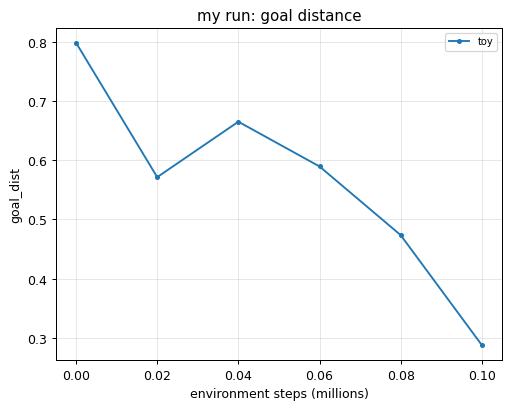

In [11]:
import tempfile, torch
from marl.common.runner import Run
from marl.algos.ddpg import DDPGConfig, train
torch.set_num_threads(2)

steps = 100_000          # ~1 min on a laptop CPU
cfg = DDPGConfig(critic="central", warmup_steps=10_000)
run = Run("toy", "speaker_listener", {}, {}, out_root=tempfile.mkdtemp(), eval_episodes=16)
train(run, "speaker_listener", {}, cfg, total_steps=steps, eval_every=20_000, label="my MADDPG")
toy = load_run(run.dir)
plot_curves([toy], "goal_dist", title="my run: goal distance");

In [12]:
show_video(video(load_policy(toy["ckpts"][-1]), "speaker_listener", {}, title="my MADDPG"))